# Mediação parental na TIC Kids Online Brasil: análise pareada e evolução temporal

**Período:** ondas de 2015 a 2025, com interrupção em 2020. **Unidade:** criança/adolescente e seu responsável na mesma linha dos microdados quando os dois relatos estão disponíveis. As ondas são cortes transversais independentes, não um painel das mesmas famílias.

Este estudo separa três medidas que não devem ser confundidas: (1) percepção da criança sobre quanto os responsáveis sabem do que ela faz na Internet (U1); (2) conversa sobre a vida online, autorrelatada pelo responsável; e (3) conversa sobre a vida online, percebida pela criança. A redação e escala mudam entre ondas: itens binários “sim/não” foram harmonizados com as escalas de frequência como **qualquer conversa versus nunca**, uma dicotomização interpretável mas que descarta intensidade.

A análise pareada só é feita nos anos em que ambos os itens estão nos microdados e têm redação correspondente. Não se infere que um informante esteja correto nem se atribui causalidade às diferenças.

## 1. Configuração e leitura dos metadados (2015–2025)

Inventariamos arquivos e dicionários, registramos hashes, examinamos os campos relevantes e lemos as descrições/categorias diretamente dos arquivos ODS. Códigos especiais e escalas são tratados de acordo com esses dicionários.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import re, hashlib, platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED=2026
B_BOOT=2000
ANOS=list(range(2015,2026))
SENTINELAS={88,97,98,99}
PALETA={"responsavel":"#087E8B","crianca":"#E08E45","gap":"#665191","conhecimento":"#4D90A6"}
RAIZ=Path.cwd()
while RAIZ!=RAIZ.parent and not (RAIZ/"dados_anuais").is_dir(): RAIZ=RAIZ.parent
PASTA_DADOS=RAIZ/"dados_anuais"
PASTA_DIC=RAIZ/"dicionarios_anuais"
assert PASTA_DADOS.is_dir() and PASTA_DIC.is_dir()
print("Raiz:",RAIZ,"| Python:",platform.python_version(),"| pandas:",pd.__version__,"| SciPy:",scipy.__version__)

NS={"table":"urn:oasis:names:tc:opendocument:xmlns:table:1.0","text":"urn:oasis:names:tc:opendocument:xmlns:text:1.0"}
def texto_celula(c): return " ".join("".join(p.itertext()) for p in c.findall(".//text:p",NS)).strip()
def ler_ods(caminho):
    linhas=[]
    with ZipFile(caminho) as arq: raiz_xml=ET.fromstring(arq.read("content.xml"))
    for tabela in raiz_xml.findall(".//table:table",NS):
        nome=tabela.get("{%s}name"%NS["table"])
        for linha in tabela.findall("table:table-row",NS):
            vals=[]
            for cel in list(linha):
                if cel.tag.split("}")[-1] in ("table-cell","covered-table-cell"):
                    v=texto_celula(cel); n=int(cel.get("{%s}number-columns-repeated"%NS["table"],"1"))
                    vals.extend([v]*min(n,30))
            if len(vals)>=3 and vals[1].strip():
                linhas.append({"aba":nome,"variável":vals[1].strip(),"descrição":vals[2].strip(),
                    "tipo":vals[3].strip() if len(vals)>3 else "","códigos":vals[4].strip() if len(vals)>4 else ""})
    return pd.DataFrame(linhas)

arquivos_dados=sorted(p for p in PASTA_DADOS.rglob("*") if p.is_file())
arquivos_dic=sorted(PASTA_DIC.rglob("*.ods"))
def extrair_ano(p):
    m=re.search(r"(?:19|20)\d{2}",p.name); return int(m.group()) if m else None
manifesto=pd.DataFrame([{"tipo":"microdados","arquivo":str(p.relative_to(RAIZ)),"ano":extrair_ano(p),"MB":round(p.stat().st_size/1e6,2),"SHA-256":hashlib.sha256(p.read_bytes()).hexdigest()} for p in arquivos_dados]+
    [{"tipo":"dicionário","arquivo":str(p.relative_to(RAIZ)),"ano":extrair_ano(p),"MB":round(p.stat().st_size/1e6,2),"SHA-256":hashlib.sha256(p.read_bytes()).hexdigest()} for p in arquivos_dic])
display(manifesto)
anos_locais={extrair_ano(p) for p in arquivos_dados if extrair_ano(p)}
print("Anos sem microdados locais:",sorted(set(ANOS)-anos_locais))
dicionarios={extrair_ano(p):ler_ods(p) for p in arquivos_dic}
print("Anos com dicionário:",sorted(dicionarios))

Raiz: /home/ymws/Documentos/mestrado/estatistica/internet | Python: 3.10.20 | pandas: 2.3.3 | SciPy: 1.15.3


,tipo,arquivo,ano,MB,SHA-256
0,microdados,dados_anuais/tic_kids_online_brasil_2015_crian...,2015,2.75,5eaae0d9e9a28627f3c54e12267615cb0e80ae4047171d...
1,microdados,dados_anuais/tic_kids_online_brasil_2016_crian...,2016,2.67,eef97695ac4dff1b00eff7dd280780c0373733c988d517...
2,microdados,dados_anuais/tic_kids_online_brasil_2017_crian...,2017,2.21,a75fad3ac331e0695e880029111647dddfe3ede66f5506...
3,microdados,dados_anuais/tic_kids_online_brasil_2018_crian...,2018,2.61,c19e8c9e8415b9083417e466ab08e56990e92eecb21fbf...
4,microdados,dados_anuais/tic_kids_online_brasil_2019_crian...,2019,2.18,83a346778c3c4f44293ae7018bbf335a9caa693ae69a88...
5,microdados,dados_anuais/tic_kids_online_brasil_2021_base_...,2021,2.58,ee38d273f30171efd64c54972afd64afb1e257715fe385...
6,microdados,dados_anuais/tic_kids_online_brasil_2022_base_...,2022,2.91,0e577bd3da5feea0e964702a607e7e7c2757fecf1d24de...
7,microdados,dados_anuais/tic_kids_online_brasil_2023_base_...,2023,3.05,0c121b55cbd90d16a81944c27dbb46c7eebe3bcb428213...
8,microdados,dados_anuais/tic_kids_online_brasil_2024_base_...,2024,8.35,d2d8354704112fa76d4ec1300ee0feaac33e40bfa295ba...
9,microdados,dados_anuais/tic_kids_online_brasil_2025_base_...,2025,8.80,dd584e11930e6316850912a6c8d259bb8ba31b5b4677eb...


Anos sem microdados locais: [2020]
Anos com dicionário: [2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025]


## 2. Harmonização das variáveis pareadas (tabela de dicionário interanual)

**U1 — conhecimento parental percebido pela criança:** em todos os dicionários disponíveis, pergunta se os pais/responsáveis “sabem muito, mais ou menos ou nada” sobre o que a criança faz na Internet. Categorias: 1 = muito, 2 = mais ou menos, 3 = nada; 97/98/99 são ausência. Mantemos a ordem e apresentamos a proporção “muito” como medida clara de maior percepção de conhecimento.

**Conversa — autorrelato do responsável e relato da criança:** 2015–2017, 2019 e 2022 usam E5_G (responsável, sim/não) e U4_G (criança, sim/não); 2018, 2021 e 2023 têm U4_G, mas não E5_G nos arquivos locais; 2024 usa E9_G e U6_G em escala 1–5; 2025 tem U6_G para a criança, mas não E9_G no arquivo local. Em 2024, 1–4 indicam alguma conversa e 5 “nunca”. A harmonização binária é sim/qualquer frequência versus não/nunca. U6_G em ondas antigas se refere a conversa com professor, não aos pais; por isso não o reutilizamos.

A tabela abaixo exibe metadados dos campos foco extraídos dos ODS e a disponibilidade efetiva dos campos nos CSVs.

In [2]:
arquivos_csv={extrair_ano(p):p for p in arquivos_dados if p.suffix.lower()==".csv" and extrair_ano(p)}
cabecalhos={ano:list(pd.read_csv(p,sep=";",nrows=0,encoding="utf-8-sig").columns) for ano,p in arquivos_csv.items()}
auditoria_pesos=pd.DataFrame([{"ano":ano,"PESO disponível":any(c.upper()=="PESO" for c in cols),
    "nº de réplicas repN":sum(bool(re.fullmatch(r"rep\d+",c,re.I)) for c in cols)} for ano,cols in cabecalhos.items()]).sort_values("ano")
display(auditoria_pesos)
FOCO={"U1","E5_G","U4_G","E9_G","U6_G"}
linhas_dic=[]
for ano in ANOS:
    dic=dicionarios.get(ano,pd.DataFrame(columns=["variável","descrição","códigos"]))
    cols={c.upper():c for c in cabecalhos.get(ano,[])}
    for var in sorted(FOCO):
        met=dic[dic["variável"].str.upper()==var] if len(dic) else dic
        if len(met):
            for _,r in met.iterrows():
                linhas_dic.append({"ano":ano,"variável":r["variável"],"presente no CSV":var in cols,
                    "descrição do dicionário":r["descrição"],"códigos":r["códigos"]})
        elif var in cols:
            linhas_dic.append({"ano":ano,"variável":var,"presente no CSV":True,"descrição do dicionário":"não localizado no ODS desta onda","códigos":"verificar"})
dicionario_interanual=pd.DataFrame(linhas_dic)
display(dicionario_interanual)

MAPA_CONVERSA={
 2015:("E5_G","U4_G"),2016:("E5_G","U4_G"),2017:("E5_G","U4_G"),
 2018:(None,"U4_G"),2019:("E5_G","U4_G"),2021:(None,"U4_G"),
 2022:("E5_G","U4_G"),2023:(None,"U4_G"),2024:("E9_G","U6_G"),2025:(None,"U6_G")
}
MAPA_U1={ano:"U1" for ano in [2015,2016,2017,2018,2019,2021,2022,2023,2024,2025]}
print("Ondas com item parental e infantil para pareamento:",[a for a,(p,c) in MAPA_CONVERSA.items() if p and c and p.upper() in [x.upper() for x in cabecalhos.get(a,[])] and c.upper() in [x.upper() for x in cabecalhos.get(a,[])]])

,ano,PESO disponível,nº de réplicas repN
0,2015,True,0
1,2016,True,0
2,2017,True,0
3,2018,True,0
4,2019,True,0
5,2021,True,0
6,2022,True,200
7,2023,True,200
8,2024,True,200
9,2025,True,200


,ano,variável,presente no CSV,descrição do dicionário,códigos
0,2015,E5_G,True,"Pensando na criança/adolescente, o responsável...","0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
1,2015,U1,True,a criança/adolescente acha que seus pais ou re...,"1 = ""Muito"" 2 = ""Mais ou menos"" 3 = ""Nada"" 97 ..."
2,2015,U4_G,True,O(s) pai(s) ou responsáveis conversa(m) com a ...,"0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
3,2015,U6_G,True,"Algum professor na escola, conversa com a cria...","0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
4,2016,E5_G,True,"Pensando na criança/adolescente, o responsável...","0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
5,2016,U1,True,A criança/adolescente acha que seus pais ou re...,"1 = ""Muito"" 2 = ""Mais ou menos"" 3 = ""Nada"" 97 ..."
6,2016,U4_G,True,O(s) pai(s) ou responsáveis conversa(m) com a ...,"0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
7,2016,U6_G,True,Algum professor na escola conversa com a crian...,"0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
8,2017,E5_G,True,"Pensando na criança/adolescente, o responsável...","0 = ""Não"" 1 = ""Sim"" 97 = ""Não sabe"" 98 = ""Não ..."
9,2017,U1,True,A criança/adolescente acha que seus pais ou re...,"1 = ""Muito"" 2 = ""Mais ou menos"" 3 = ""Nada"" 97 ..."


Ondas com item parental e infantil para pareamento: [2015, 2016, 2017, 2019, 2022, 2024]


## 3. Análise descritiva longitudinal (pais vs. crianças)

As curvas comparam amostras anuais independentes. Para cada proporção apresentamos IC95% de Wilson sem ajuste para desenho e uma estimativa pontual com PESO quando disponível. Os pesos replicados e parâmetros de variância não estão sendo presumidos; portanto, intervalos e testes clássicos não sustentam inferência nacional.

In [3]:
def coluna_por_nome(cols,nome): return {c.upper():c for c in cols}.get(nome.upper())
def ler_onda(ano,campos):
    p=arquivos_csv.get(ano)
    if p is None: return None
    cols=cabecalhos[ano]; mapa={c.upper():c for c in cols}
    escolhidas={k:mapa.get(v.upper()) for k,v in campos.items() if v}
    use=list(dict.fromkeys([v for v in escolhidas.values() if v]+([mapa["PESO"]] if "PESO" in mapa else [])))
    if not use: return None
    d=pd.read_csv(p,sep=";",decimal=",",usecols=use,encoding="utf-8-sig",low_memory=False)
    ren={orig:novo for novo,orig in escolhidas.items() if orig}
    if "PESO" in mapa: ren[mapa["PESO"]]="peso"
    d=d.rename(columns=ren); d["ano"]=ano
    if "peso" not in d: d["peso"]=1.0
    for c in [*escolhidas.keys(),"peso"]:
        if c in d: d[c]=pd.to_numeric(d[c],errors="coerce")
    return d

ondas=[]
for ano in sorted(MAPA_CONVERSA):
    par,cri=MAPA_CONVERSA[ano]
    campos={"ID_DOMICILIO":"ID_DOMICILIO","resp_raw":par,"cri_raw":cri,"U1_raw":MAPA_U1.get(ano)}
    d=ler_onda(ano,campos)
    if d is None: continue
    # Normalização do relato de conversa: qualquer frequência versus nunca;
    # nos questionários binários, preserva sim/não.
    if "resp_raw" in d:
        d["responsavel_conversa"]=np.where(d.resp_raw.isin([0,1]),d.resp_raw, np.where(d.resp_raw.isin([1,2,3,4]),1,np.where(d.resp_raw.eq(5),0,np.nan)))
        # Resolver código 1 compartilhado entre sim binário e escala de frequência.
        if par and par.upper()=="E5_G": d["responsavel_conversa"]=d.resp_raw.where(d.resp_raw.isin([0,1]))
    else: d["responsavel_conversa"]=np.nan
    if "cri_raw" in d:
        d["crianca_conversa"]=np.where(d.cri_raw.isin([0,1]),d.cri_raw, np.where(d.cri_raw.isin([1,2,3,4]),1,np.where(d.cri_raw.eq(5),0,np.nan)))
        if cri and cri.upper()=="U4_G": d["crianca_conversa"]=d.cri_raw.where(d.cri_raw.isin([0,1]))
    else: d["crianca_conversa"]=np.nan
    if "U1_raw" in d:
        d["conhecimento_percebido"]=d.U1_raw.where(d.U1_raw.isin([1,2,3]))
    else: d["conhecimento_percebido"]=np.nan
    d["gap_conversa"]=d.responsavel_conversa-d.crianca_conversa
    d["discordancia"]=d.responsavel_conversa.ne(d.crianca_conversa).where(d[["responsavel_conversa","crianca_conversa"]].notna().all(axis=1))
    ondas.append(d)
dados=pd.concat(ondas,ignore_index=True) if ondas else pd.DataFrame()
fluxo=dados.groupby("ano").agg(registros=("ano","size"),domicílios_distintos=("ID_DOMICILIO","nunique"),
    ids_duplicados=("ID_DOMICILIO",lambda s:int(s.duplicated().sum())),U1_validos=("conhecimento_percebido","count"),
    relatos_responsavel_validos=("responsavel_conversa","count"),relatos_crianca_validos=("crianca_conversa","count"),
    pares_validos=("gap_conversa","count")).reset_index()
display(fluxo)
assert (fluxo.ids_duplicados==0).all(), "IDs de domicílio repetidos: verificar o pareamento antes de testar."
print("Nota: 2020 não aparece porque a pesquisa não foi realizada; ausência de E5_G em alguns CSVs impede pareamento, não significa resposta negativa.")

,ano,registros,domicílios_distintos,ids_duplicados,U1_validos,relatos_responsavel_validos,relatos_crianca_validos,pares_validos
0,2015,3068,3068,0,2440,2409,2456,2324
1,2016,2999,2999,0,2481,2425,2482,2335
2,2017,3102,3102,0,2635,2614,2648,2519
3,2018,2964,2964,0,2581,0,2591,0
4,2019,2954,2954,0,2645,2676,2653,2581
5,2021,2939,2939,0,2610,0,2638,0
6,2022,2604,2604,0,2305,2366,2321,2264
7,2023,2704,2704,0,2367,0,2373,0
8,2024,2686,2686,0,2403,2467,2410,2332
9,2025,2642,2642,0,2344,0,2346,0


Nota: 2020 não aparece porque a pesquisa não foi realizada; ausência de E5_G em alguns CSVs impede pareamento, não significa resposta negativa.


### 3.1 Proporções por onda e intervalos

Para U1 apresentamos “pais sabem muito” e “pais sabem muito ou mais ou menos”. Para conversa, comparamos autorrelato parental e percepção infantil na mesma definição binária. As proporções ponderadas são estimativas pontuais descritivas.

In [4]:
def ic_wilson(k,n):
    if n==0:return (np.nan,np.nan)
    z=stats.norm.ppf(.975); p=k/n; den=1+z*z/n
    centro=(p+z*z/(2*n))/den; margem=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return centro-margem,centro+margem
def proporcao_ponderada(y,w):
    ok=pd.notna(y)&pd.notna(w)&(w>0)
    return float(np.average(np.asarray(y)[ok],weights=np.asarray(w)[ok])) if ok.any() else np.nan

linhas=[]
for ano,g in dados.groupby("ano"):
    for nome,col,fun in [("Responsável: alguma conversa","responsavel_conversa",lambda s:s.eq(1)),
                         ("Criança: percebe alguma conversa","crianca_conversa",lambda s:s.eq(1)),
                         ("Criança: pais sabem muito (U1)","conhecimento_percebido",lambda s:s.eq(1)),
                         ("Criança: pais sabem muito/mais ou menos (U1)","conhecimento_percebido",lambda s:s.isin([1,2]))]:
        s=g[col].dropna()
        if s.empty: continue
        y=fun(s).astype(int); lo,hi=ic_wilson(int(y.sum()),len(y))
        w=g.loc[s.index,"peso"]
        linhas.append({"ano":ano,"indicador":nome,"n":len(y),"proporção":y.mean(),"IC95% inferior":lo,"IC95% superior":hi,
                       "proporção ponderada (PESO)":proporcao_ponderada(y,w)})
descritivas=pd.DataFrame(linhas)
display(descritivas.round(4))
u1=descritivas[descritivas.indicador=="Criança: pais sabem muito (U1)"].sort_values("ano")
if len(u1)>=2:
    display(Markdown(f"**Leitura descritiva de U1:** a proporção não ponderada ‘pais sabem muito’ foi {u1.iloc[0].proporção:.1%} em {int(u1.iloc[0].ano)} e {u1.iloc[-1].proporção:.1%} em {int(u1.iloc[-1].ano)}. A comparação é entre cortes transversais e não é, por si só, um teste de tendência."))

,ano,indicador,n,proporção,IC95% inferior,IC95% superior,proporção ponderada (PESO)
0,2015,Responsável: alguma conversa,2409,0.7563,0.7388,0.7731,0.7479
1,2015,Criança: percebe alguma conversa,2456,0.6914,0.6728,0.7093,0.6897
2,2015,Criança: pais sabem muito (U1),2440,0.4770,0.4573,0.4969,0.4865
3,2015,Criança: pais sabem muito/mais ou menos (U1),2440,0.8918,0.8789,0.9035,0.8938
4,2016,Responsável: alguma conversa,2425,0.7806,0.7637,0.7966,0.7721
5,2016,Criança: percebe alguma conversa,2482,0.7188,0.7008,0.7361,0.7114
6,2016,Criança: pais sabem muito (U1),2481,0.4724,0.4528,0.4921,0.4586
7,2016,Criança: pais sabem muito/mais ou menos (U1),2481,0.9012,0.8889,0.9124,0.8937
8,2017,Responsável: alguma conversa,2614,0.8057,0.7900,0.8204,0.8150
9,2017,Criança: percebe alguma conversa,2648,0.7292,0.7120,0.7458,0.7159


**Leitura descritiva de U1:** a proporção não ponderada ‘pais sabem muito’ foi 47.7% em 2015 e 57.4% em 2025. A comparação é entre cortes transversais e não é, por si só, um teste de tendência.

## 4. Testes pareados ano a ano (replicação 2015–2025)

A série harmonizada “alguma conversa versus nunca/não” é binária. O teste principal por onda é McNemar exato, com diferença pareada de proporções e IC95% bootstrap por reamostragem das díades. Cohen κ e AC1 de Gwet descrevem concordância. Holm ajusta os p-valores de McNemar entre as ondas pareadas.

Como sensibilidade específica de 2024, reproduzimos o Wilcoxon ordinal de E9_G × U6_G conforme o notebook de referência; a estatística ordinal não é comparável aos anos binários.

In [5]:
def kappa_ac1(a,b):
    a=np.asarray(a,int);b=np.asarray(b,int);n=len(a)
    tab=np.zeros((2,2),float)
    for x,y in zip(a,b):tab[x,y]+=1
    po=np.trace(tab)/n; pa=tab[1,:].sum()/n; pb=tab[:,1].sum()/n
    pe_k=pa*pb+(1-pa)*(1-pb)
    kap=(po-pe_k)/(1-pe_k) if pe_k<1 else np.nan
    pbar=(pa+pb)/2; pe_a=2*pbar*(1-pbar)
    ac1=(po-pe_a)/(1-pe_a) if pe_a<1 else np.nan
    return kap,ac1
def bootstrap_pareado(a,b,B=B_BOOT,seed=SEED):
    a=np.asarray(a,int);b=np.asarray(b,int);n=len(a);rng=np.random.default_rng(seed)
    idx=rng.integers(0,n,size=(B,n)); dif=[];kap=[];ac=[]
    for ix in idx:
        d=a[ix]-b[ix]; dif.append(d.mean());k,x=kappa_ac1(a[ix],b[ix]);kap.append(k);ac.append(x)
    return {"dif":np.quantile(dif,[.025,.975]),"kappa":np.nanquantile(kap,[.025,.975]),"ac1":np.nanquantile(ac,[.025,.975])}

linhas=[]
for ano,g0 in dados.groupby("ano"):
    g=g0.dropna(subset=["responsavel_conversa","crianca_conversa"]).copy()
    if not len(g):continue
    a=g.responsavel_conversa.astype(int).to_numpy();b=g.crianca_conversa.astype(int).to_numpy()
    n10=int(((a==1)&(b==0)).sum());n01=int(((a==0)&(b==1)).sum());discord=n10+n01
    pex=stats.binomtest(n10,discord,p=.5).pvalue if discord else 1.0
    ci=bootstrap_pareado(a,b,seed=SEED+int(ano));kap,ac1=kappa_ac1(a,b)
    peso=g.peso.to_numpy(float);ok=np.isfinite(peso)&(peso>0)
    prop_resp_peso=float(np.average(a[ok],weights=peso[ok])) if ok.any() else np.nan
    prop_cri_peso=float(np.average(b[ok],weights=peso[ok])) if ok.any() else np.nan
    linhas.append({"ano":ano,"n díades":len(g),"responsável sim (%)":a.mean(),"criança sim (%)":b.mean(),
      "diferença pareada":(a-b).mean(),"IC95% diferença inf":ci["dif"][0],"IC95% diferença sup":ci["dif"][1],
      "responsável com PESO":prop_resp_peso,"criança com PESO":prop_cri_peso,"diferença com PESO":prop_resp_peso-prop_cri_peso,
      "discordâncias resp sim/criança não":n10,"discordâncias resp não/criança sim":n01,"p McNemar exato":pex,
      "κ Cohen":kap,"IC95% κ inf":ci["kappa"][0],"IC95% κ sup":ci["kappa"][1],
      "AC1 Gwet":ac1,"IC95% AC1 inf":ci["ac1"][0],"IC95% AC1 sup":ci["ac1"][1]})
pareados=pd.DataFrame(linhas)
if len(pareados):
    pareados["p McNemar Holm"]=multipletests(pareados["p McNemar exato"],method="holm")[1]
    display(pareados)
    n_sig=int((pareados["p McNemar Holm"]<.05).sum())
    display(Markdown(f"**Leitura dos testes pareados:** em {n_sig} de {len(pareados)} ondas, a diferença entre a proporção que relata alguma conversa foi significativa após Holm. A estimativa é {pareados.iloc[-1]['diferença pareada']:.1%} em 2024 (IC95% bootstrap {pareados.iloc[-1]['IC95% diferença inf']:.1%} a {pareados.iloc[-1]['IC95% diferença sup']:.1%}); diferença positiva indica relato de conversa mais frequente pelo responsável que pela criança. Isso não identifica qual relato é mais correto."))
else:print("Não há díades com ambos os relatos válidos nos arquivos locais.")
status_pareamento=[]
anos_testados=set(pareados.ano) if len(pareados) else set()
for ano in ANOS:
    if ano==2020: estado="onda não realizada"
    elif ano in anos_testados: estado="teste pareado executado"
    elif ano in arquivos_csv: estado="não estimável: variável de autorrelato parental ausente no CSV"
    else: estado="microdados não localizados"
    status_pareamento.append({"ano":ano,"status da comparação pareada":estado})
display(pd.DataFrame(status_pareamento))

# Sensibilidade ordinal 2024 (mesma pergunta e escala 1–5 da referência).
g24=dados[(dados.ano==2024)&dados.resp_raw.isin([1,2,3,4,5])&dados.cri_raw.isin([1,2,3,4,5])].copy()
if len(g24):
    x=6-g24.resp_raw.to_numpy();y=6-g24.cri_raw.to_numpy();d=x-y
    wil=stats.wilcoxon(x,y,zero_method="wilcox",alternative="two-sided",method="approx")
    def rb_func(v):
        v=np.asarray(v);v=v[v!=0]
        if len(v)==0:return np.nan
        rr=stats.rankdata(np.abs(v));return (rr[v>0].sum()-rr[v<0].sum())/rr.sum()
    r_rb=rb_func(d);rng=np.random.default_rng(SEED+24)
    rb_boot=[rb_func(d[ix]) for ix in rng.integers(0,len(d),size=(B_BOOT,len(d)))]
    rb_ci=np.nanquantile(rb_boot,[.025,.975])
    print(f"2024 ordinal: n={len(d)}, W={wil.statistic:.1f}, p={wil.pvalue:.3g}, r bisserial={r_rb:.3f}, IC95% bootstrap [{rb_ci[0]:.3f}; {rb_ci[1]:.3f}]. O resultado de referência (n=2.332) é reproduzido na amostra pareada válida.")

,ano,n díades,responsável sim (%),criança sim (%),diferença pareada,IC95% diferença inf,IC95% diferença sup,responsável com PESO,criança com PESO,diferença com PESO,discordâncias resp sim/criança não,discordâncias resp não/criança sim,p McNemar exato,κ Cohen,IC95% κ inf,IC95% κ sup,AC1 Gwet,IC95% AC1 inf,IC95% AC1 sup,p McNemar Holm
0,2015,2324,0.757745,0.704389,0.053356,0.031411,0.074021,0.750219,0.699917,0.050302,370,246,6.632084e-07,0.328348,0.286045,0.369080,0.563172,0.527959,0.595543,6.632084e-07
1,2016,2335,0.782013,0.723340,0.058672,0.038533,0.079229,0.775784,0.715524,0.060260,384,247,5.489919e-08,0.277503,0.235876,0.318477,0.569477,0.536165,0.602858,1.097984e-07
2,2017,2519,0.805478,0.734815,0.070663,0.050417,0.089321,0.811770,0.719458,0.092312,428,250,8.122096e-12,0.245089,0.203494,0.288024,0.583326,0.552122,0.614951,2.436629e-11
3,2019,2581,0.820225,0.742735,0.077489,0.058495,0.096862,0.820311,0.738664,0.081648,437,237,1.147621e-14,0.242065,0.199089,0.284192,0.603411,0.572415,0.633794,4.590482e-14
4,2022,2264,0.825088,0.692138,0.132951,0.111296,0.153280,0.866268,0.717512,0.148756,466,165,3.655589e-34,0.256924,0.215212,0.300126,0.560228,0.525780,0.597034,2.193354e-33
5,2024,2332,0.888079,0.801029,0.087050,0.068611,0.105918,0.902901,0.761183,0.141718,351,148,4.617338e-20,0.196635,0.148711,0.245277,0.709833,0.679418,0.737883,2.308669e-19


**Leitura dos testes pareados:** em 6 de 6 ondas, a diferença entre a proporção que relata alguma conversa foi significativa após Holm. A estimativa é 8.7% em 2024 (IC95% bootstrap 6.9% a 10.6%); diferença positiva indica relato de conversa mais frequente pelo responsável que pela criança. Isso não identifica qual relato é mais correto.

,ano,status da comparação pareada
0,2015,teste pareado executado
1,2016,teste pareado executado
2,2017,teste pareado executado
3,2018,não estimável: variável de autorrelato parenta...
4,2019,teste pareado executado
5,2020,onda não realizada
6,2021,não estimável: variável de autorrelato parenta...
7,2022,teste pareado executado
8,2023,não estimável: variável de autorrelato parenta...
9,2024,teste pareado executado


2024 ordinal: n=2332, W=228424.5, p=3.29e-76, r bisserial=0.557, IC95% bootstrap [0.510; 0.602]. O resultado de referência (n=2.332) é reproduzido na amostra pareada válida.


## 5. Testes de tendência temporal (percepção dos filhos, percepção dos pais e evolução do gap)

Regressões logísticas com ano contínuo avaliam a tendência da probabilidade de (a) a criança responder “muito” em U1, (b) responder “muito/mais ou menos”, (c) perceber alguma conversa e (d) o responsável relatar alguma conversa. A inclinação é apresentada como OR por ano, IC95%, estatística de Wald (χ², 1 gl) e p-valor. Para o gap, modelamos tanto a discordância binária (OR por ano) quanto a diferença líquida entre relatos (OLS HC3). HC3 é uma correção clássica; não reproduz estratos, conglomerados ou pesos da pesquisa. Holm ajusta a família de tendências.

In [6]:
def tendencia_logistica(frame,col,titulo):
    s=frame[["ano",col]].dropna().copy();s["y"]=s[col].astype(int)
    if s.ano.nunique()<3 or s.y.nunique()<2:
        return {"desfecho":titulo,"ondas":s.ano.nunique(),"n":len(s),"OR/ano":np.nan,"β gap/ano":np.nan,"IC95% inferior":np.nan,"IC95% superior":np.nan,"Wald χ²":np.nan,"gl":1,"p":np.nan,"status":"não estimável"}
    fit=sm.GLM(s.y,sm.add_constant(s.ano.astype(float)),family=sm.families.Binomial()).fit(cov_type="HC3")
    beta=float(fit.params["ano"]);lo,hi=fit.conf_int().loc["ano"];wald=float(fit.tvalues["ano"]**2)
    return {"desfecho":titulo,"ondas":s.ano.nunique(),"n":len(s),"OR/ano":np.exp(beta),"β gap/ano":np.nan,"IC95% inferior":np.exp(lo),"IC95% superior":np.exp(hi),"Wald χ²":wald,"gl":1,"p":float(fit.pvalues["ano"]),"status":"estimado; logístico HC3, análise não ponderada"}

trend=dados.copy()
trend["U1_muito"]=trend.conhecimento_percebido.eq(1).where(trend.conhecimento_percebido.notna())
trend["U1_muito_ou_mais"]=trend.conhecimento_percebido.isin([1,2]).where(trend.conhecimento_percebido.notna())
trend["crianca_conversa_bin"]=trend.crianca_conversa
trend["responsavel_conversa_bin"]=trend.responsavel_conversa
trend["discordancia_bin"]=trend.discordancia.astype(float)
res_tend=[tendencia_logistica(trend,c,n) for c,n in [
 ("U1_muito","Criança: percepção de que os pais sabem muito (U1)"),
 ("U1_muito_ou_mais","Criança: percepção de que os pais sabem ao menos mais ou menos (U1)"),
 ("crianca_conversa_bin","Criança: percebe alguma conversa parental"),
 ("responsavel_conversa_bin","Responsável: relata alguma conversa")]]
res_tend.append(tendencia_logistica(trend,"discordancia_bin","Gap: discordância entre relatos"))
# Tendência do gap líquido (relato do responsável menos relato da criança).
gap=trend[["ano","gap_conversa"]].dropna().copy()
if gap.ano.nunique()>=3:
    fit_gap=sm.OLS(gap.gap_conversa,sm.add_constant(gap.ano.astype(float))).fit(cov_type="HC3")
    beta=float(fit_gap.params["ano"]);lo,hi=fit_gap.conf_int().loc["ano"]
    linha_gap={"desfecho":"Gap líquido: responsável − criança","ondas":gap.ano.nunique(),"n":len(gap),
      "OR/ano":np.nan,"β gap/ano":beta,"IC95% inferior":lo,"IC95% superior":hi,"Wald χ²":float(fit_gap.tvalues["ano"]**2),
      "gl":1,"p":float(fit_gap.pvalues["ano"]),"status":"estimado; OLS HC3, escala binária"}
else:
    linha_gap={"desfecho":"Gap líquido: responsável − criança","ondas":gap.ano.nunique(),"n":len(gap),
      "OR/ano":np.nan,"β gap/ano":np.nan,"IC95% inferior":np.nan,"IC95% superior":np.nan,"Wald χ²":np.nan,"gl":1,"p":np.nan,"status":"não estimável"}
res_tend.append(linha_gap)
tendencias=pd.DataFrame(res_tend)
ps=tendencias["p"].dropna()
tendencias["p Holm"]=np.nan
if len(ps):tendencias.loc[ps.index,"p Holm"]=multipletests(ps,method="holm")[1]
display(tendencias)
for _,r in tendencias.dropna(subset=["p"]).iterrows():
    aumento=(r["OR/ano"]>1 if pd.notna(r["OR/ano"]) else r["IC95% inferior"]>0)
    verbo=("aumentaram" if aumento else "diminuíram") if pd.notna(r["OR/ano"]) else ("aumentou" if aumento else "diminuiu")
    medida="as chances" if pd.notna(r["OR/ano"]) else "o gap líquido"
    if pd.isna(r["p Holm"]) or r["p Holm"]>=.05:
        frase="não houve evidência estatística suficiente de tendência após Holm"
    else:
        frase=f"{medida} {verbo} ao longo das ondas (p Holm={r['p Holm']:.3g})"
    display(Markdown(f"**Interpretação — {r['desfecho']}:** {frase}. Estimativa não ponderada com HC3; associação entre cortes transversais independentes."))
linha_gap= tendencias[tendencias.desfecho=="Gap líquido: responsável − criança"].iloc[0]
linha_disc=tendencias[tendencias.desfecho=="Gap: discordância entre relatos"].iloc[0]
if pd.notna(linha_gap["β gap/ano"]):
    display(Markdown(f"**Síntese do gap:** a probabilidade de discordância teve OR/ano {linha_disc['OR/ano']:.3f} (IC95% {linha_disc['IC95% inferior']:.3f}–{linha_disc['IC95% superior']:.3f}; p Holm={linha_disc['p Holm']:.3g}), enquanto o gap líquido responsável−criança mudou {100*linha_gap['β gap/ano']:.2f} ponto percentual por ano (IC95% {100*linha_gap['IC95% inferior']:.2f} a {100*linha_gap['IC95% superior']:.2f}; p Holm={linha_gap['p Holm']:.3g}). As duas medidas captam aspectos diferentes: frequência de discordância e direção líquida."))

,desfecho,ondas,n,OR/ano,β gap/ano,IC95% inferior,IC95% superior,Wald χ²,gl,p,status,p Holm
0,Criança: percepção de que os pais sabem muito ...,10,24811,1.035421,NaN,1.027569,1.043333,80.315078,1,3.192239e-19,"estimado; logístico HC3, análise não ponderada",1.596120e-18
1,Criança: percepção de que os pais sabem ao men...,10,24811,1.045136,NaN,1.030177,1.060312,36.024829,1,1.948192e-09,"estimado; logístico HC3, análise não ponderada",7.792767e-09
2,Criança: percebe alguma conversa parental,10,24918,1.019726,NaN,1.011295,1.028228,21.264380,1,4.000975e-06,"estimado; logístico HC3, análise não ponderada",8.001950e-06
3,Responsável: relata alguma conversa,6,14957,1.084324,NaN,1.069813,1.099032,138.698684,1,5.126143e-32,"estimado; logístico HC3, análise não ponderada",3.075686e-31
4,Gap: discordância entre relatos,6,14355,0.979620,NaN,0.968276,0.991096,12.006349,1,5.301962e-04,"estimado; logístico HC3, análise não ponderada",5.301962e-04
5,Gap líquido: responsável − criança,6,14355,NaN,0.006045,0.003540,0.008551,22.366524,1,2.252664e-06,"estimado; OLS HC3, escala binária",6.757993e-06


**Interpretação — Criança: percepção de que os pais sabem muito (U1):** as chances aumentaram ao longo das ondas (p Holm=1.6e-18). Estimativa não ponderada com HC3; associação entre cortes transversais independentes.

**Interpretação — Criança: percepção de que os pais sabem ao menos mais ou menos (U1):** as chances aumentaram ao longo das ondas (p Holm=7.79e-09). Estimativa não ponderada com HC3; associação entre cortes transversais independentes.

**Interpretação — Criança: percebe alguma conversa parental:** as chances aumentaram ao longo das ondas (p Holm=8e-06). Estimativa não ponderada com HC3; associação entre cortes transversais independentes.

**Interpretação — Responsável: relata alguma conversa:** as chances aumentaram ao longo das ondas (p Holm=3.08e-31). Estimativa não ponderada com HC3; associação entre cortes transversais independentes.

**Interpretação — Gap: discordância entre relatos:** as chances diminuíram ao longo das ondas (p Holm=0.00053). Estimativa não ponderada com HC3; associação entre cortes transversais independentes.

**Interpretação — Gap líquido: responsável − criança:** o gap líquido aumentou ao longo das ondas (p Holm=6.76e-06). Estimativa não ponderada com HC3; associação entre cortes transversais independentes.

**Síntese do gap:** a probabilidade de discordância teve OR/ano 0.980 (IC95% 0.968–0.991; p Holm=0.00053), enquanto o gap líquido responsável−criança mudou 0.60 ponto percentual por ano (IC95% 0.35 a 0.86; p Holm=6.76e-06). As duas medidas captam aspectos diferentes: frequência de discordância e direção líquida.

## 6. Visualizações comparativas e síntese dos resultados

As bandas dos gráficos são IC95% de Wilson não ajustados ao desenho amostral. As séries representam amostras anuais distintas; lacunas indicam ano sem coleta ou sem variável necessária. O gap pareado positivo significa maior proporção de “alguma conversa” no relato do responsável que na percepção da criança.

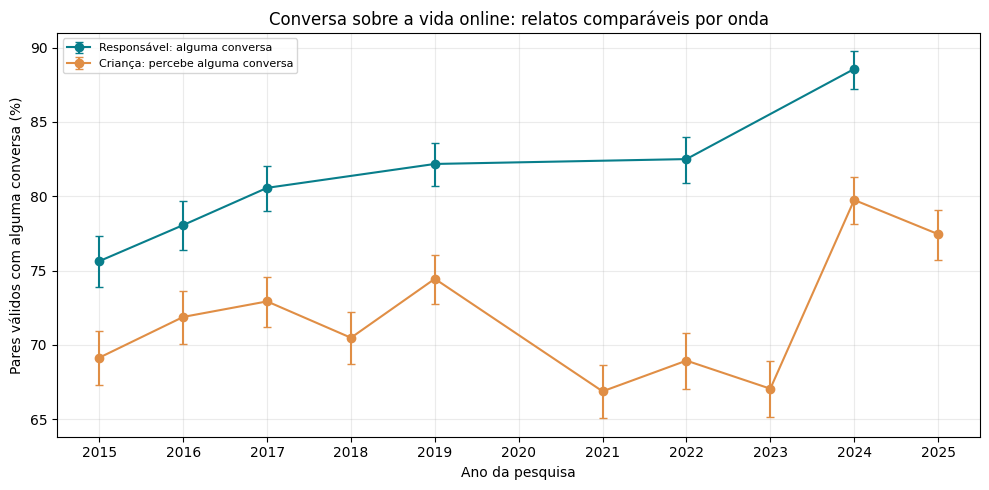

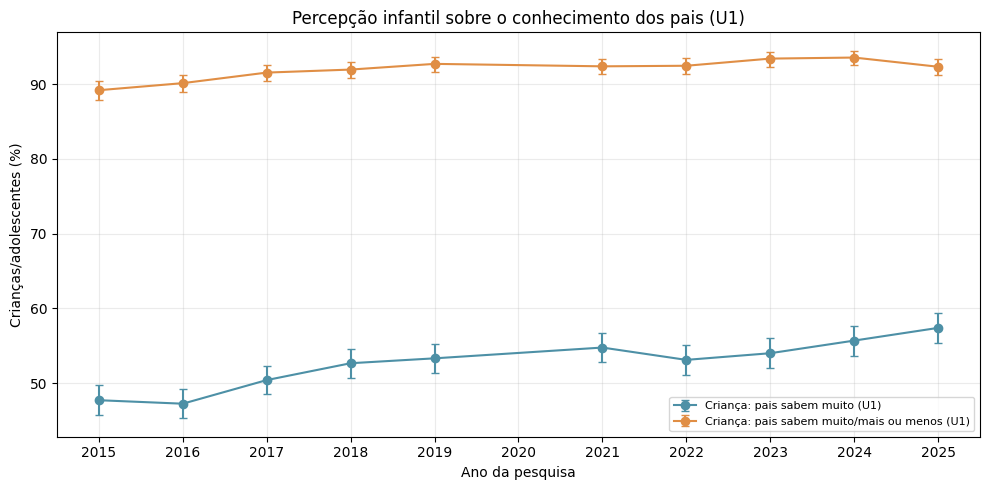

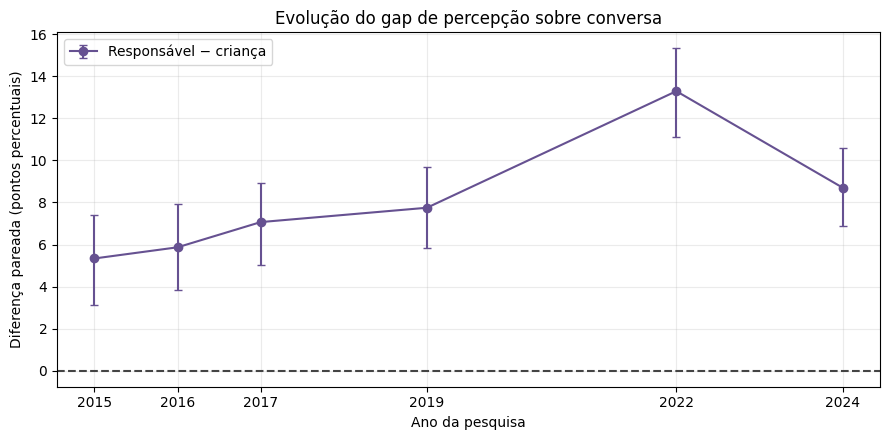

Síntese: as tendências são associações temporais em cortes transversais repetidos. Leia OR/ano e ICs junto às mudanças de escala e aos anos sem item parental. Nenhuma inferência nacional é liberada sem variância por desenho.


In [7]:
def grafico_serie(indicadores,titulo,ylabel,cores):
    fig,ax=plt.subplots(figsize=(10,5))
    for nome,col,cor in indicadores:
        sub=descritivas[descritivas.indicador==nome].sort_values("ano")
        if sub.empty:continue
        ax.errorbar(sub.ano.to_numpy(),100*sub.proporção.to_numpy(),
            yerr=[100*(sub.proporção-sub["IC95% inferior"]).to_numpy(),100*(sub["IC95% superior"]-sub.proporção).to_numpy()],
            marker="o",capsize=3,label=nome,color=cor)
    ax.set(title=titulo,xlabel="Ano da pesquisa",ylabel=ylabel,xticks=sorted(ANOS));ax.grid(alpha=.25);ax.legend(fontsize=8);plt.tight_layout();plt.show()

grafico_serie([("Responsável: alguma conversa","responsavel_conversa",PALETA["responsavel"]),("Criança: percebe alguma conversa","crianca_conversa",PALETA["crianca"])],
    "Conversa sobre a vida online: relatos comparáveis por onda","Pares válidos com alguma conversa (%)",PALETA)
grafico_serie([("Criança: pais sabem muito (U1)","U1_muito",PALETA["conhecimento"]),("Criança: pais sabem muito/mais ou menos (U1)","U1_muito/mais",PALETA["crianca"])],
    "Percepção infantil sobre o conhecimento dos pais (U1)","Crianças/adolescentes (%)",PALETA)

if len(pareados):
    fig,ax=plt.subplots(figsize=(9,4.5));s=pareados.sort_values("ano")
    ax.errorbar(s.ano,100*s["diferença pareada"],yerr=[100*(s["diferença pareada"]-s["IC95% diferença inf"]),100*(s["IC95% diferença sup"]-s["diferença pareada"])],marker="o",capsize=3,color=PALETA["gap"],label="Responsável − criança")
    ax.axhline(0,color="#444",linestyle="--");ax.set(title="Evolução do gap de percepção sobre conversa",xlabel="Ano da pesquisa",ylabel="Diferença pareada (pontos percentuais)",xticks=s.ano);ax.grid(alpha=.25);ax.legend();plt.tight_layout();plt.show()

print("Síntese: as tendências são associações temporais em cortes transversais repetidos. Leia OR/ano e ICs junto às mudanças de escala e aos anos sem item parental. Nenhuma inferência nacional é liberada sem variância por desenho.")

### Síntese e limites

- **Percepção infantil de atenção/conhecimento:** U1 é uma medida ordinal explícita da percepção de quanto os pais sabem sobre as atividades online. Ela está disponível em todos os anos com microdados listados; 2020 não teve pesquisa.
- **Mediação parental:** o item “conversa sobre o que faz na Internet” pode ser harmonizado como alguma conversa versus nunca/não, mas reduz escala de frequência a binário. Os relatos pareados locais estão disponíveis apenas quando os dois campos existem.
- **Gap:** as diferenças anuais são entre díades distintas por onda; a evolução temporal não acompanha as mesmas famílias.
- Os microdados disponíveis incluem PESO; use-o para estimativas pontuais descritivas. Não interprete p-valores/ICs clássicos como inferência nacional sem estratos, conglomerados e parâmetros de replicação confirmados.
- A TIC Kids Online não foi realizada em 2020 porque as restrições à coleta presencial e a complexidade da adaptação impediram a implementação da pesquisa: [relatório oficial da edição 2020](https://cetic.br/media/docs/publicacoes/2/20211125083634/tic_kids_online_2020_livro_eletronico.pdf).

**Formulação recomendada:** “Nas ondas com resposta válida, os relatos de conversa do responsável e da criança foram comparados dentro da díade. A percepção infantil de quanto os responsáveis conhecem sua vida online foi analisada separadamente como tendência temporal. As medidas não são intercambiáveis e diferenças entre informantes não indicam qual relato é verdadeiro.”